In [51]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from typing import TypedDict

In [52]:
load_dotenv()

True

In [53]:
llm = ChatGoogleGenerativeAI(
    model = 'gemini-2.5-flash'
)

In [54]:
#define state

class BlogState(TypedDict):
    topic: str
    blog: str
    outline: str
    



In [55]:
def gen_blog_outline(state: BlogState) -> BlogState:

    # extract the topic
    topic = state['topic']

    #form a prompt
    prompt = f'You are the expert blog writer write only a clear outline for the blog on the topic - {topic}'


    #ask question to LLm
    outline = llm.invoke(prompt).content


    #update answer to the state 
    state['outline'] = outline

    return state


In [56]:
def write_blog(state: BlogState) -> BlogState:

    # extract the outline 
    outline = state['outline']
    topic = state['topic']

    #form a prompt
    prompt = f'You are the expert blog writer write a short blog on the title - {topic} using the following outlines \n {outline}'


    #ask question to LLm
    blog = llm.invoke(prompt).content


    #update answer to the state 
    state['blog'] = blog

    return state


In [57]:
#create graph
graph = StateGraph(BlogState)

#Add node
graph.add_node('gen_blog_outline', gen_blog_outline)
graph.add_node('write_blog', write_blog)
#Add Edges
graph.add_edge(START, 'gen_blog_outline')
graph.add_edge('gen_blog_outline', 'write_blog')
graph.add_edge('write_blog', END)

#Compile
workflow = graph.compile()

In [58]:
#execute
intail_state = {'topic': 'What is Procastination?'}
final_state = workflow.invoke(intail_state)

print(final_state['outline'])

Here's a clear outline for a blog post on "What is Procrastination?":

---

**Blog Post Title Idea:** Beyond Laziness: Unpacking the True Nature of Procrastination

**I. Introduction**
    A. **Hook:** Relatable scenario – the looming deadline, the guilt, the "I'll do it later" mantra.
    B. **Common Misconception:** Briefly state that procrastination is often mistaken for laziness or poor time management.
    C. **Thesis Statement:** Introduce the true definition of procrastination as a complex psychological phenomenon, primarily an emotional regulation problem.
    D. **What to Expect:** Outline that the post will clarify what procrastination truly is, why we do it (briefly), and its subtle impacts.

**II. Defining Procrastination: More Than Just Delay**
    A. **Core Definition:**
        1.  The voluntary delay of an intended course of action.
        2.  Despite knowing there will be negative consequences.
    B. **Key Distinctions (What it ISN'T):**
        1.  **Not Laziness:**

In [59]:
print(final_state['blog'])

## Beyond Laziness: Unpacking the True Nature of Procrastination

We've all been there: staring at a looming deadline, the guilt gnawing at us, yet somehow finding endless reasons to scroll through social media, clean the entire house, or suddenly become fascinated by obscure documentaries. The familiar mantra, "I'll do it later," echoes in our minds.

Often, this cycle is dismissed as simple laziness or poor time management. But what if we told you it's far more complex than that? Procrastination isn't a character flaw; it's a fascinating and often frustrating psychological phenomenon, primarily rooted in how we regulate our emotions. This post will clarify what procrastination truly is, briefly touch upon why we engage in it, and shed light on its subtle, yet significant, impacts.

### Defining Procrastination: More Than Just Delay

At its core, procrastination is the **voluntary delay of an intended course of action, despite knowing there will be negative consequences.**

It’s cruci

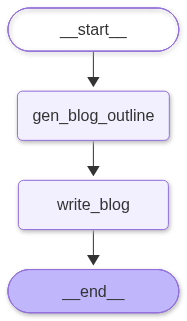

In [25]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())